In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [3]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

In [4]:
x = np.random.uniform(1, 3, size=10000)
x_err = np.random.uniform(0.1, 0.5, size=10000) + x * 0.6
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

### Fit

In [ ]:
from garden.api.fitter import FlowVI
from garden.transfer import neglogplus

In [6]:
flow_vi = FlowVI(x_min=0,
                 x_max=x_obs.max(),
                 x_err_min=0,
                 x_err_max=x_err.max() * 1.2,
                 transfer=neglogplus,
                 transfer_params=[np.median(x_obs),
                                  np.median(x_err)])

In [7]:
flow_vi.fit(x_obs,
            x_err,
            n_pre=100,
            n_train=1000,
            n_node=21,
            verbose=True,
            x_min=0,
            x_max=x_obs.max(),
            x_err_min=0,
            x_err_max=x_err.max() * 1.2,
            check_per_step=10,
            early_stop=True,
            max_stuck=5,
            stuck_frac=0.01)

100%|██████████| 100/100 [00:07<00:00, 12.94it/s]


step 0: loss 1.8899352550506592
step 10: loss 1.6357207298278809
step 20: loss 1.6085044145584106
step 30: loss 1.5971794128417969
step 40: loss 1.5919911861419678
step 50: loss 1.5890042781829834
step 60: loss 1.5868406295776367
step 70: loss 1.5860785245895386
step 80: loss 1.5843536853790283


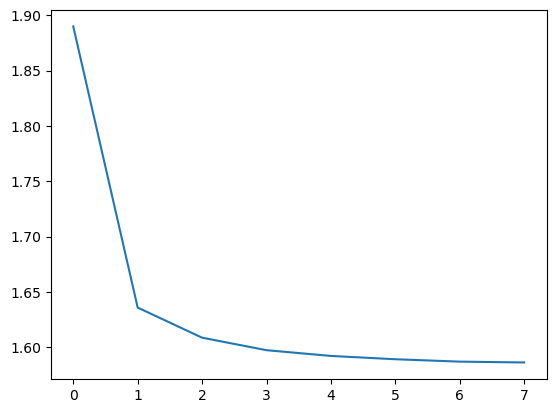

In [8]:
plt.plot(flow_vi.loss)

In [9]:
x_gen, x_err_gen, x_obs_gen = flow_vi.sample(10000,
                                             0,
                                             x_obs.max(),
                                             0,
                                             x_err.max() * 1.2,
                                             return_numpy=True)

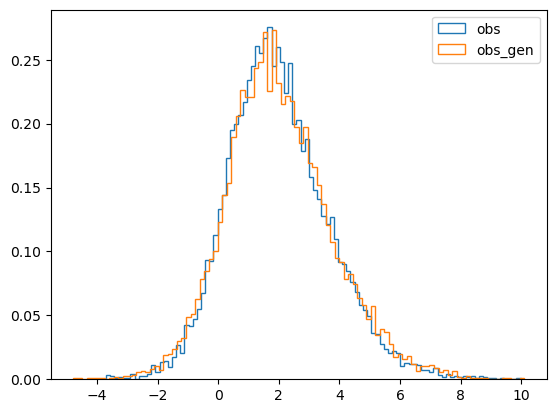

In [10]:
plt.hist(x_obs, bins=100, histtype='step', density=True, label='obs');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');
plt.legend()

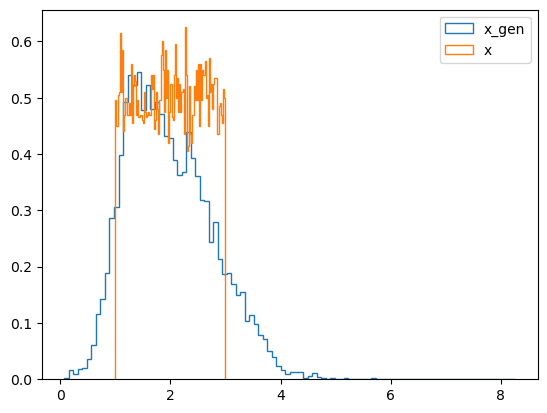

In [11]:
plt.hist(x_gen, bins=100, histtype='step', density=True, label='x_gen');
plt.hist(x, bins=100, histtype='step', density=True, label='x');
plt.legend()

In [12]:
flow_vi.ks_test(x_obs, x_err, 10000)

(0.02025001496076584, 0.13127312894381335)

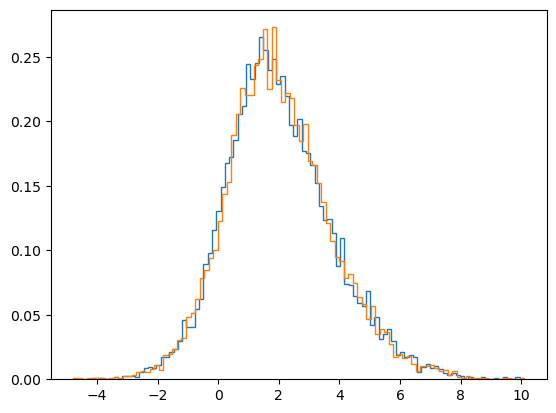

In [13]:
! rm -rf test

flow_vi.save('test')
flow_loaded = FlowVI.load('test')

x_gen_load, x_err_gen_load, x_obs_gen_load = flow_loaded.sample(10000, 0, x_obs.max(), 0, x_err.max() * 1.2, return_numpy=True)

plt.hist(x_obs_gen_load, bins=100, histtype='step', density=True, label='obs_gen_load');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');

# remove the folder
! rm -rf test